# 05 — HCO, VNLS và HCO–VNLS trên một evaluator cố định

**Câu hỏi trọng tâm:** Với cùng model, cùng cutoff và cùng ngân sách đánh giá mask, phương pháp lai có cải thiện AP hoặc tạo tập feature gọn hơn hai phương pháp riêng lẻ không?

Pilot dùng HGB nhanh làm evaluator, thay vì đổi model giữa các thuật toán. HCO–VNLS được đánh giá trên **validation chưa dùng trong fitness**; không mặc định lai luôn thắng AP. Cần phân biệt `fitness` (có thưởng ít feature) với AP thuần.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / 'clht_code').exists():
    ROOT = ROOT.parents[1]
sys.path.insert(0, str(ROOT))
from NghienCuu_HCO_VNLS.code_dung_chung.thuc_nghiem import (
    GOC, NGHIEN_CUU, DATA, KET_QUA, HINH, CAC_MOC,
    tao_thu_muc, duong_dan, chia_nhom, nap_du_lieu, chon_dac_trung,
    tien_xu_ly, bo_sung_ty_le, bo_sung_cua_so_vle,
)
tao_thu_muc()
print('Dữ liệu nguồn:', DATA)
print('Kết quả riêng:', KET_QUA)

Dữ liệu nguồn: CLHT_GB_GITHUB\data
Kết quả riêng: CLHT_GB_GITHUB\NghienCuu_HCO_VNLS\ket_qua


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.ensemble import HistGradientBoostingClassifier
from clht_code.models import ModelConfig, make_pipeline
from clht_code.evaluation import metric_table
from clht_code.optimizers import MaskObjective, run_search_budgeted

config = ModelConfig('HGB_search_60', HistGradientBoostingClassifier(max_iter=60, learning_rate=.08,
                            max_leaf_nodes=12, early_stopping=False, random_state=41))
methods = ('HCO', 'VNLS', 'HCO-VNLS')
cutoffs = (.5, .75)
seeds = (41, 77)
budget = 8
alpha = .85
print({'model': config.name, 'budget_uncached_calls': budget, 'seeds': seeds, 'alpha': alpha})

{'model': 'HGB_search_60', 'budget_uncached_calls': 8, 'seeds': (41, 77), 'alpha': 0.85}


## 1. Fitness và ranh giới đánh giá

Mask là một dãy 0/1, mỗi bit ứng với một feature gốc. Công thức pilot giữ nguyên đề tài:

`fitness = α × AP_CV + (1 − α) × (1 − số_feature_chọn / tổng_feature)`

AP_CV là trung bình GroupKFold trên **train**; validation được đánh giá một lần cho mỗi mask cuối. Budget ở đây chỉ 8 lần gọi objective không nằm cache cho mỗi phương pháp và seed, đủ làm pilot có thể chạy lại, **chưa đủ để chứng minh tối ưu toàn cục**.

In [3]:
rows = []
histories = []
for cutoff in cutoffs:
    frame = nap_du_lieu(cutoff)
    features = chon_dac_trung(frame)
    train, valid = (frame[frame.split == value] for value in ('train', 'validation'))
    X_train, X_valid = train[features], valid[features]
    for seed in seeds:
        for method in methods:
            objective = MaskObjective(X_train, train.risk.to_numpy(), train.id_student.to_numpy(), config, alpha=alpha)
            search = run_search_budgeted(method, objective, seed=seed, budget=budget, population=3)
            selected = search['selected_columns']
            pipeline = make_pipeline(X_train[selected], config)
            pipeline.fit(X_train[selected], train.risk)
            probability = pipeline.predict_proba(X_valid[selected])[:, 1]
            metrics = metric_table(valid.risk, probability)
            rows.append({'cutoff': cutoff, 'seed': seed, 'method': method, 'features': len(selected),
                         'selected_columns': '|'.join(selected), 'fitness_cv': search['fitness_cv'],
                         'ap_cv': search['average_precision_cv'], 'objective_calls': search['objective_calls'],
                         'search_seconds': search['wall_seconds'], **metrics})
            histories.extend({'cutoff': cutoff, 'seed': seed, 'method': method, 'step': step,
                              'best_fitness': value} for step, value in enumerate(search['history']))
            print(cutoff, seed, method, len(selected), round(metrics['average_precision_risk'], 4))
result = pd.DataFrame(rows)
result.to_csv(KET_QUA/'hco_vnls_validation.csv', index=False, encoding='utf-8-sig')
history = pd.DataFrame(histories)
history.to_csv(KET_QUA/'hco_vnls_hoi_tu.csv', index=False, encoding='utf-8-sig')
display(result.groupby(['cutoff','method'])[['accuracy','recall_risk','f1_risk','average_precision_risk','fitness_cv','features','search_seconds']].agg(['mean','std']).round(4))

Python312\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "Python312\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "Python312\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "Python312\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "Python312\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^

0.5 41 HCO 17 0.8471


0.5 41 VNLS 16 0.8469


0.5 41 HCO-VNLS 16 0.8455


0.5 77 HCO 21 0.8492


0.5 77 VNLS 15 0.8395


... (4 outputs left out)

0.75 77 HCO 21 0.8946


0.75 77 VNLS 15 0.888


0.75 77 HCO-VNLS 17 0.8945


accuracy         recall_risk         f1_risk          \
                    mean     std        mean     std    mean     std   
cutoff method                                                          
0.50   HCO        0.8103  0.0004      0.6180  0.0071  0.7134  0.0019   
       HCO-VNLS   0.8105  0.0033      0.6104  0.0117  0.7111  0.0075   
       VNLS       0.8090  0.0000      0.6068  0.0086  0.7082  0.0029   
0.75   HCO        0.8720  0.0021      0.6834  0.0079  0.7849  0.0047   
       HCO-VNLS   0.8742  0.0023      0.6907  0.0012  0.7896  0.0033   
       VNLS       0.8706  0.0025      0.6894  0.0042  0.7845  0.0022   

                average_precision_risk         fitness_cv         features  \
                                  mean     std       mean     std     mean   
cutoff method                                                                
0.50   HCO                      0.8481  0.0015     0.7910  0.0085     19.0   
       HCO-VNLS                 0.8460  0.0007     0.8011  0.0017     16.5   
       VNLS                     0.8432  0.0053     0.8026  0.0011     15.5   
0.75   HCO                      0.8935  0.0016     0.8288  0.0065     19.0   
       HCO-VNLS                 0.8954  0.0012     0.8387  0.0013     17.0   
       VNLS                     0.8902  0.0031     0.8411  0.0014     15.5   

                        search_seconds          
                    std           mean     std  
cutoff method                                   
0.50   HCO       2.8284        10.6339  0.0339  
       HCO-VNLS  0.7071        10.0322  1.0991  
       VNLS      0.7071        10.1624  0.7042  
0.75   HCO       2.8284        10.2420  1.1574  
       HCO-VNLS  0.0000        10.2243  0.3294  
       VNLS      0.7071         8.5133  0.6056

## 1b. Đối chứng đúng cùng evaluator, không dùng optimizer

HGB 60 vòng với đầy đủ feature là đối chứng bắt buộc cho tác động của chọn feature. HGB 160 vòng trong notebook 03 không cùng cấu hình, không được dùng để quy chênh lệch riêng cho HCO/VNLS.

In [4]:
full_rows = []
for cutoff in cutoffs:
    frame = nap_du_lieu(cutoff)
    features = chon_dac_trung(frame)
    train, valid = (frame[frame.split == value] for value in ('train','validation'))
    pipeline = make_pipeline(train[features], config)
    pipeline.fit(train[features], train.risk)
    full_rows.append({'cutoff': cutoff, 'method': 'Full features', 'features': len(features),
                      **metric_table(valid.risk, pipeline.predict_proba(valid[features])[:,1])})
full = pd.DataFrame(full_rows)
full.to_csv(KET_QUA/'hco_vnls_du_feature_validation.csv', index=False, encoding='utf-8-sig')
display(full[['cutoff','features','accuracy','recall_risk','average_precision_risk']].round(4))

,cutoff,features,accuracy,recall_risk,average_precision_risk
0,0.50,38,0.8112,0.6209,0.8500
1,0.75,38,0.8747,0.6907,0.8975


## 2. Hình hội tụ và cách kết luận

Đường fitness tăng không đồng nghĩa AP validation tăng: phần thưởng độ gọn cũng nằm trong fitness. Hãy đọc bảng ở trên trước khi kết luận phương pháp lai tốt hơn.

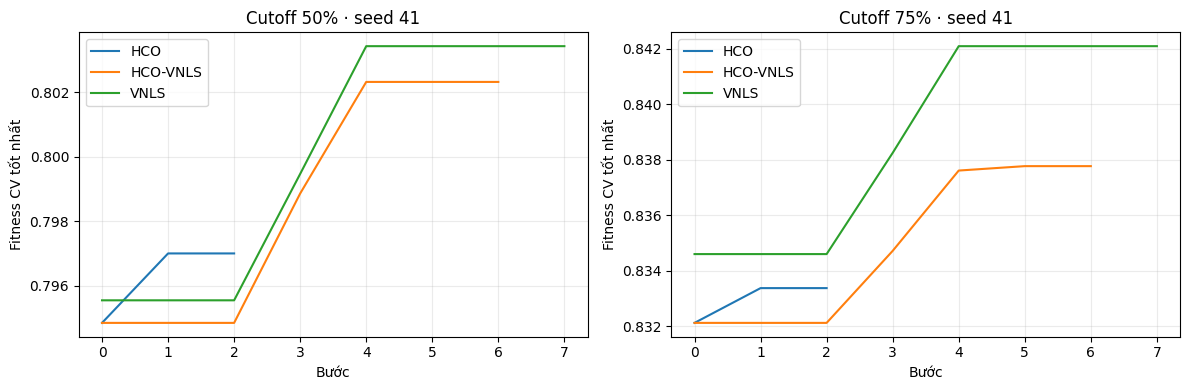

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for axis, cutoff in zip(axes, cutoffs):
    for method, group in history[(history.cutoff == cutoff) & (history.seed == seeds[0])].groupby('method'):
        axis.plot(group.step, group.best_fitness, label=method)
    axis.set(title=f'Cutoff {cutoff:.0%} · seed {seeds[0]}', xlabel='Bước', ylabel='Fitness CV tốt nhất')
    axis.grid(alpha=.25); axis.legend()
fig.tight_layout(); fig.savefig(HINH/'hco_vnls_hoi_tu.png', dpi=160); plt.show()

**Giới hạn của pilot:** hai seed và budget nhỏ chỉ giúp thử quy trình. Nếu phương pháp lai đứng đầu một chỉ số, cần mở rộng số seed/budget và kiểm tra độ lệch chuẩn trước khi viết kết luận chính thức.

## Kết quả đọc nhanh — lần chạy 23/09/2026

Ở 50%, AP validation trung bình của HCO–VNLS là `0,8460` với `16,5` feature; HCO là `0,8481` với `19` feature. Ở 75%, hybrid là `0,8954` với `17` feature, cao hơn hai thuật toán riêng lẻ trong pilot, nhưng thấp hơn **cùng HGB 60 vòng** dùng đủ `38` feature (`0,8975`). Nói chính xác: **lai đang tạo đánh đổi độ gọn/chất lượng; chưa chứng minh luôn thắng AP.** Cần tăng budget và số seed.